<a href="https://colab.research.google.com/github/bahaali273/COMP9170-Hospital-Readmission/blob/bahaa-dev/notebooks/Bootstrap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP 9170 — Random Forest Bootstrap Confidence Intervals

**Purpose:** quantify uncertainty in held-out test performance (PR-AUC / Average Precision, ROC-AUC, precision, recall, F1).

**Method:** 1,000 patient-level bootstrap samples from the held-out test rows; do not refit models or change the fixed validation-selected classification threshold (0.33). One encounter per patient is assumed, as described by the project; confirm in the preprocessing audit.

**Caution:** this assesses sampling uncertainty on this historical test cohort, *not* data leakage, calibration, external transportability, or clinical validity.

In [6]:

# ============================================================
# COMP 9170 — Bootstrap Confidence Intervals
# Step 1: Load Random Forest Model and Prepared Test Dataset
# Environment: Google Colab
# ============================================================

import io
import joblib
import requests
import numpy as np
import pandas as pd

from google.colab import files

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Load the trained Random Forest model from GitHub
# ------------------------------------------------------------

print("Loading Random Forest model from GitHub...")

base_url = (
    "https://raw.githubusercontent.com/"
    "bahaali273/COMP9170-Hospital-Readmission/"
    "master/models/"
)

parts = []

for part_number in range(1, 4):
    url = base_url + f"rf_model.part{part_number:02d}"

    response = requests.get(url, timeout=90)
    response.raise_for_status()

    parts.append(response.content)
    print(f"Downloaded model part {part_number}")

# Only load joblib files from a trusted repository.
bundle = joblib.load(io.BytesIO(b"".join(parts)))

model = bundle["model"]
feature_names = list(bundle["feature_names"])
threshold = float(bundle["threshold"])

print("\nModel loaded successfully!")
print("Model:", type(model).__name__)
print("Expected features:", len(feature_names))
print("Classification threshold:", threshold)

# ------------------------------------------------------------
# 2. Upload the prepared test dataset
# ------------------------------------------------------------

print("\nPlease upload test_clean.csv")

uploaded = files.upload()


# Accept the uploaded CSV even if Colab renamed it
csv_files = [
    name for name in uploaded
    if name.lower().endswith(".csv")
]

if len(csv_files) != 1:
    raise ValueError(
        f"Expected one uploaded CSV file, found: {csv_files}"
    )

uploaded_filename = csv_files[0]

print("Using file:", uploaded_filename)

test_df = pd.read_csv(
    io.BytesIO(uploaded[uploaded_filename])
)

print("Test dataset loaded successfully!")
print("Dataset shape:", test_df.shape)


print("\nTest dataset loaded successfully!")
print("Dataset shape:", test_df.shape)

# ------------------------------------------------------------
# 3. Validate dataset and feature compatibility
# ------------------------------------------------------------

target_col = "readmit_30"

required_columns = feature_names + [target_col]

missing_columns = [
    col for col in required_columns
    if col not in test_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

X_test = test_df.loc[:, feature_names]
y_test = test_df[target_col].astype(int).to_numpy()

if X_test.isna().any().any():
    raise ValueError(
        "The test dataset contains missing feature values."
    )

if not set(np.unique(y_test)).issubset({0, 1}):
    raise ValueError(
        "Expected binary target labels 0 and 1."
    )

classes = list(model.classes_)

if 1 not in classes:
    raise ValueError(
        "The model does not contain positive class 1."
    )

assert X_test.shape[1] == model.n_features_in_

# ------------------------------------------------------------
# 4. Generate predictions using the fixed threshold
# ------------------------------------------------------------

positive_index = classes.index(1)

probs = model.predict_proba(X_test)[:, positive_index]

preds = (probs >= threshold).astype(int)

# ------------------------------------------------------------
# 5. Display verification results
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FINAL DATA AND MODEL VERIFICATION")
print("=" * 55)

print(f"Test patients: {len(y_test):,}")

print(
    f"Positive labels: {np.sum(y_test):,} "
    f"({np.mean(y_test):.2%})"
)

print(f"Features: {X_test.shape[1]}")

print(f"Fixed decision threshold: {threshold:.2f}")

print(
    "First 5 predicted probabilities:",
    np.round(probs[:5], 4)
)

print("\nBaseline model performance:")
print(
    "PR-AUC:",
    round(average_precision_score(y_test, probs), 4)
)
print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, probs), 4)
)
print(
    "Precision:",
    round(precision_score(y_test, preds, zero_division=0), 4)
)
print(
    "Recall:",
    round(recall_score(y_test, preds, zero_division=0), 4)
)
print(
    "F1:",
    round(f1_score(y_test, preds, zero_division=0), 4)
)

print("\nSTEP 1 COMPLETED SUCCESSFULLY!")


Loading Random Forest model from GitHub...
Downloaded model part 1
Downloaded model part 2
Downloaded model part 3

Model loaded successfully!
Model: RandomForestClassifier
Expected features: 133
Classification threshold: 0.33

Please upload test_clean.csv


Saving test_clean.csv to test_clean (3).csv
Using file: test_clean (3).csv
Test dataset loaded successfully!
Dataset shape: (13994, 134)

Test dataset loaded successfully!
Dataset shape: (13994, 134)

FINAL DATA AND MODEL VERIFICATION
Test patients: 13,994
Positive labels: 1,255 (8.97%)
Features: 133
Fixed decision threshold: 0.33
First 5 predicted probabilities: [0.0983 0.1564 0.0926 0.443  0.4021]

Baseline model performance:
PR-AUC: 0.1558
ROC-AUC: 0.6455
Precision: 0.1617
Recall: 0.408
F1: 0.2316

STEP 1 COMPLETED SUCCESSFULLY!


## Fixed model evaluation and paired bootstrap resampling

The bootstrap resamples *test patients*, keeping each sampled patient’s true label and predicted probability paired. No model selection, resampling for class balance, or threshold tuning takes place on the test set. These are percentile bootstrap intervals, not guarantees of future-hospital performance.

In [9]:

# ============================================================
# COMP 9170 — Random Forest Bootstrap Confidence Intervals
# Google Colab
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

def calculate_metrics(y, p, fixed_threshold):
    pred = (p >= fixed_threshold).astype(int)

    results = {
        "PR-AUC (Average Precision)": average_precision_score(y, p),
        "ROC-AUC": roc_auc_score(y, p),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
    }

    return results


# Calculate original test-set performance
point_estimates = calculate_metrics(y_test, probs, threshold)

# Bootstrap settings
N_BOOTSTRAP = 1000
rng = np.random.default_rng(42)

n = len(y_test)
bootstrap_results = []

# Bootstrap resampling
for i in range(N_BOOTSTRAP):
    idx = rng.integers(0, n, size=n)

    y_sample = y_test[idx]
    p_sample = probs[idx]

    # Skip samples containing only one target class
    if np.unique(y_sample).size < 2:
        continue

    bootstrap_results.append(
        calculate_metrics(
            y_sample,
            p_sample,
            threshold
        )
    )


# Calculate 95% confidence intervals
boot_df = pd.DataFrame(bootstrap_results)

rows = []

for name, point_value in point_estimates.items():
    low, high = np.percentile(
        boot_df[name],
        [2.5, 97.5]
    )

    rows.append({
        "Metric": name,
        "Estimate": point_value,
        "CI 95% Lower": low,
        "CI 95% Upper": high,
    })


# Display results
results_df = pd.DataFrame(rows)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:.4f}"
)

print(f"Successful bootstrap repetitions: {len(boot_df):,}")
print(results_df.to_string(index=False))


# ============================================================
# Save results to Google Colab
# ============================================================

output_dir = Path("/content/bootstrap_results")
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "rf_bootstrap_metrics.csv"

results_df.to_csv(
    csv_path,
    index=False
)

print("\nSaved:", csv_path)
print("BOOTSTRAP ANALYSIS COMPLETED SUCCESSFULLY!")


Successful bootstrap repetitions: 1,000
                    Metric  Estimate  CI 95% Lower  CI 95% Upper
PR-AUC (Average Precision)    0.1558        0.1434        0.1707
                   ROC-AUC    0.6455        0.6296        0.6615
                 Precision    0.1617        0.1493        0.1748
                    Recall    0.4080        0.3799        0.4355
                        F1    0.2316        0.2160        0.2485

Saved: /content/bootstrap_results/rf_bootstrap_metrics.csv
BOOTSTRAP ANALYSIS COMPLETED SUCCESSFULLY!


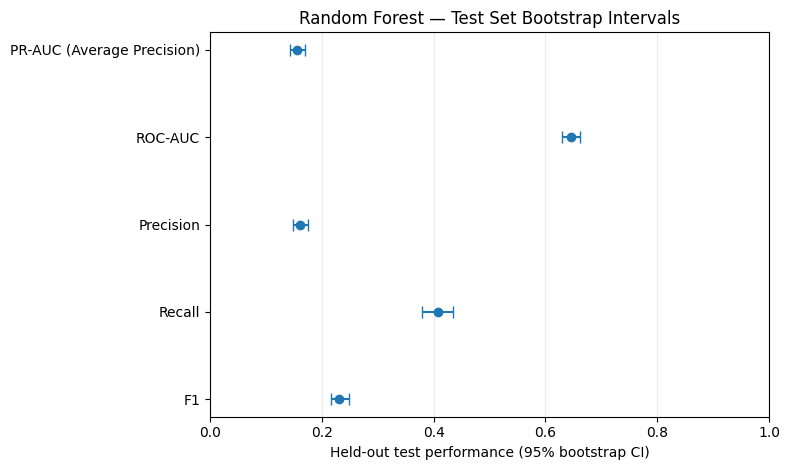

Saved: /content/bootstrap_results/rf_bootstrap_confidence_intervals.png


In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.8))
y_positions = np.arange(len(results_df))
values = results_df["Estimate"].to_numpy()
lower = results_df["CI 95% Lower"].to_numpy()
upper = results_df["CI 95% Upper"].to_numpy()

ax.errorbar(
    values, y_positions,
    xerr=np.vstack((values - lower, upper - values)),
    fmt="o", capsize=4
)
ax.set_yticks(y_positions, results_df["Metric"])
ax.invert_yaxis()
ax.set_xlabel("Held-out test performance (95% bootstrap CI)")
ax.set_title("Random Forest — Test Set Bootstrap Intervals")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
chart_path = output_dir / "rf_bootstrap_confidence_intervals.png"
fig.savefig(chart_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", chart_path)